In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

from src import data_toolkit as dt
from src import portfolio_toolkit as pt

In [3]:
inds_rets = dt.get_ind_returns(n_inds=12, weighting = "vw")
inds_rets

,NoDur,Durbl,Manuf,Enrgy,Chems,BusEq,Telcm,Utils,Shops,Hlth,Money,Other
Date,,,,,,,,,,,,
1926-07,0.0144,0.1558,0.0367,-0.0114,0.0802,0.0315,0.0083,0.0704,0.0012,0.0185,-0.0002,0.0223
1926-08,0.0399,0.0370,0.0241,0.0343,0.0510,0.0198,0.0217,-0.0170,-0.0072,0.0417,0.0426,0.0435
1926-09,0.0115,0.0498,-0.0007,-0.0330,0.0538,-0.0035,0.0242,0.0205,0.0021,0.0069,-0.0163,0.0039
1926-10,-0.0124,-0.0839,-0.0318,-0.0078,-0.0455,-0.0538,-0.0011,-0.0327,-0.0229,-0.0057,-0.0552,-0.0275
1926-11,0.0521,-0.0017,0.0403,0.0001,0.0509,0.0479,0.0163,0.0440,0.0645,0.0543,0.0254,0.0211
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03,-0.0805,-0.0803,-0.0977,0.1285,-0.0901,-0.0474,-0.0261,-0.0205,-0.0431,-0.0723,-0.0346,-0.0669
2026-04,0.0267,0.0332,0.0925,-0.0415,0.0204,0.1782,-0.0226,0.0205,0.1177,-0.0206,0.0911,0.0407
2026-05,-0.0024,0.1203,0.0506,-0.0607,-0.0198,0.1198,-0.0146,-0.0497,-0.0289,0.0295,-0.0080,0.0005


In [4]:
inds_rets.isna().sum()

NoDur    0
Durbl    0
Manuf    0
Enrgy    0
Chems    0
BusEq    0
Telcm    0
Utils    0
Shops    0
Hlth     0
Money    0
Other    0
dtype: int64

In [5]:
inds_mc = dt.get_ind_market_caps(n_inds=12, weights = True)
inds_mc.sum(axis = 1)

Date
1926-07    1.0
1926-08    1.0
1926-09    1.0
1926-10    1.0
1926-11    1.0
          ... 
2026-03    1.0
2026-04    1.0
2026-05    1.0
2026-06    1.0
2026-07    1.0
Freq: M, Length: 1201, dtype: float64

In [6]:
ff_factors = dt.get_fff_returns()
ff_factors

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07,0.0289,-0.0242,-0.0275,0.0022
1926-08,0.0264,-0.0144,0.0413,0.0025
1926-09,0.0038,-0.0136,0.0005,0.0023
1926-10,-0.0327,-0.0018,0.0078,0.0032
1926-11,0.0254,-0.0017,-0.0048,0.0031
...,...,...,...,...
2026-03,-0.0518,0.0044,0.0329,0.0029
2026-04,0.0995,0.0019,-0.0137,0.0029
2026-05,0.0491,-0.0159,-0.0231,0.0031


In [10]:
ff_factors.isna().sum()

Mkt-RF    0
SMB       0
HML       0
RF        0
dtype: int64

In [83]:
rf = ff_factors["RF"]
rf.shape

(1201,)

In [24]:
inds_rets['NoDur'].index

PeriodIndex(['1926-07', '1926-08', '1926-09', '1926-10', '1926-11', '1926-12',
             '1927-01', '1927-02', '1927-03', '1927-04',
             ...
             '2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03',
             '2026-04', '2026-05', '2026-06', '2026-07'],
            dtype='period[M]', name='Date', length=1201)

In [27]:
pt.summary_stats(inds_rets)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
NoDur,0.105427,0.157910,-0.072271,8.569484,0.061333,0.098964,0.464715,-0.667440
Durbl,0.105347,0.285315,1.053415,13.791271,0.079466,0.170005,0.256682,-0.902625
Manuf,0.106325,0.231077,0.886416,14.996825,0.065122,0.142698,0.321201,-0.898884
Enrgy,0.105062,0.222350,0.226812,7.195027,0.085499,0.132334,0.328295,-0.771274
Chems,0.104453,0.195666,0.394854,11.457344,0.066836,0.115316,0.370110,-0.853939
BusEq,0.115246,0.255030,0.361237,9.799969,0.091390,0.158225,0.325012,-0.920719
Telcm,0.088046,0.161428,-0.045917,5.739022,0.066509,0.101839,0.349778,-0.720354
Utils,0.092174,0.188222,0.103157,10.488836,0.070672,0.120993,0.321265,-0.847809
Shops,0.109642,0.200208,-0.012027,8.923177,0.077934,0.123756,0.386925,-0.841533
Hlth,0.115718,0.190466,0.080144,9.627067,0.071115,0.113349,0.437797,-0.747917


In [28]:
corr = inds_rets.corr()
corr

,NoDur,Durbl,Manuf,Enrgy,Chems,BusEq,Telcm,Utils,Shops,Hlth,Money,Other
NoDur,1.000000,0.671917,0.819341,0.603309,0.831825,0.715637,0.677460,0.704859,0.846804,0.787406,0.823148,0.808418
Durbl,0.671917,1.000000,0.813416,0.546929,0.747020,0.747716,0.575055,0.558466,0.759137,0.583170,0.746701,0.754023
Manuf,0.819341,0.813416,1.000000,0.697077,0.881540,0.850640,0.662673,0.672948,0.827712,0.727607,0.863407,0.910340
Enrgy,0.603309,0.546929,0.697077,1.000000,0.651703,0.570758,0.518889,0.577668,0.561646,0.534745,0.662571,0.663006
Chems,0.831825,0.747020,0.881540,0.651703,1.000000,0.778472,0.655763,0.679890,0.797540,0.752533,0.808396,0.810779
BusEq,0.715637,0.747716,0.850640,0.570758,0.778472,1.000000,0.657790,0.612907,0.792862,0.704161,0.779120,0.811764
Telcm,0.677460,0.575055,0.662673,0.518889,0.655763,0.657790,1.000000,0.616465,0.666785,0.590878,0.704684,0.678647
Utils,0.704859,0.558466,0.672948,0.577668,0.679890,0.612907,0.616465,1.000000,0.640990,0.609859,0.747067,0.672540
Shops,0.846804,0.759137,0.827712,0.561646,0.797540,0.792862,0.666785,0.640990,1.000000,0.734436,0.822922,0.811068
Hlth,0.787406,0.583170,0.727607,0.534745,0.752533,0.704161,0.590878,0.609859,0.734436,1.000000,0.741826,0.713084


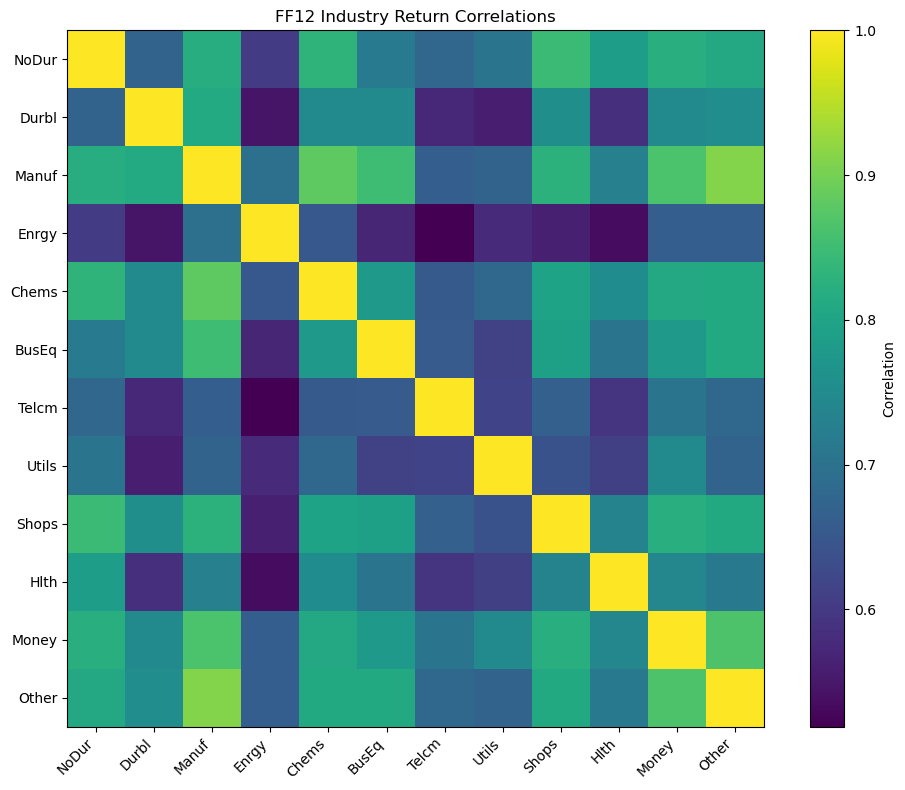

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

fig.colorbar(im, ax=ax, label="Correlation")

plt.title("FF12 Industry Return Correlations")
plt.tight_layout()
plt.show()

<Axes: xlabel='Date'>

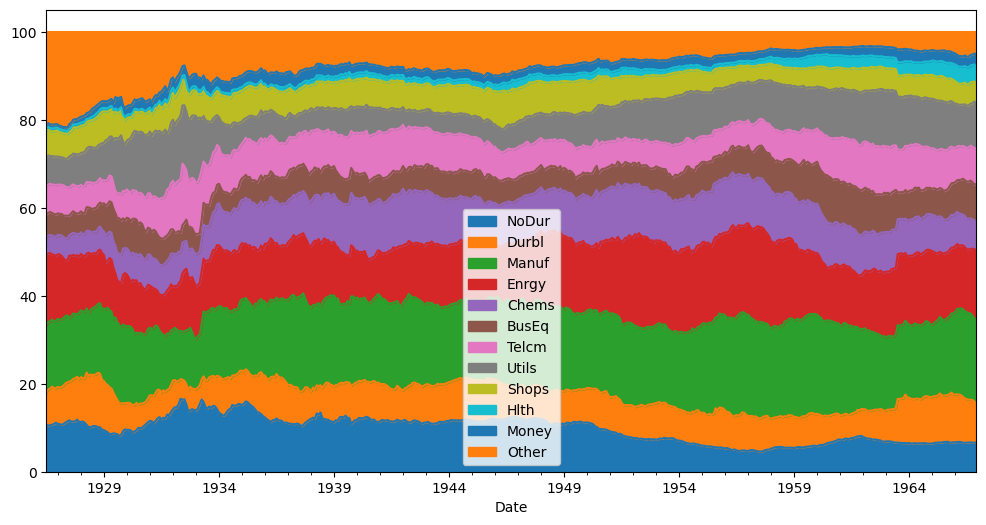

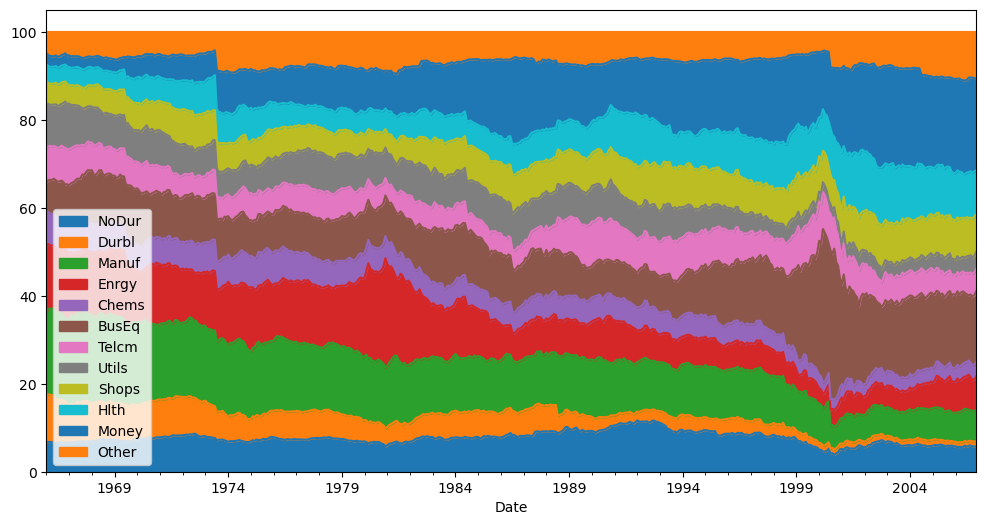

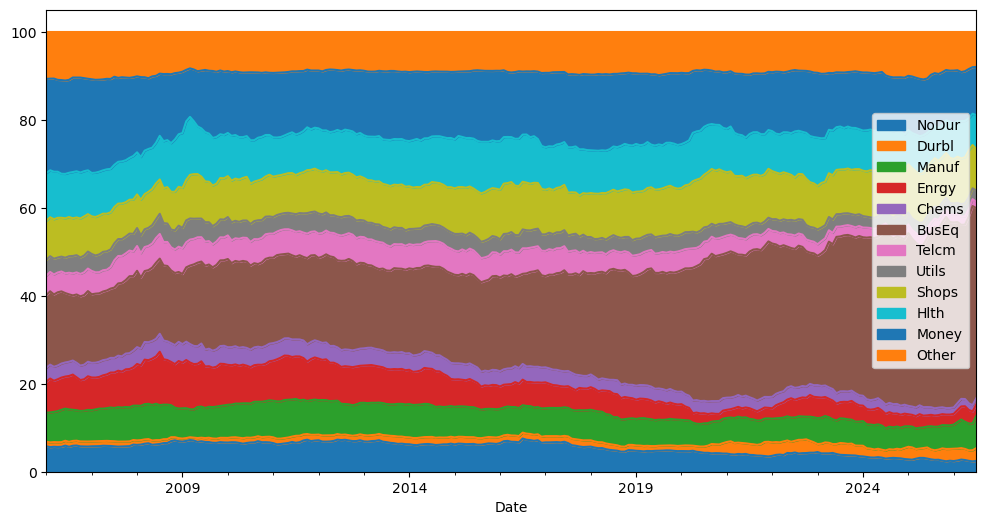

In [30]:
(inds_mc["1926":"1966"]* 100).plot.area(figsize = (12,6))
(inds_mc["1966":"2006"]* 100).plot.area(figsize = (12,6))
(inds_mc["2006":"2026"]* 100).plot.area(figsize = (12,6))

In [50]:
import pandas as pd

In [63]:
inds_excess= inds_rets.sub(rf, axis = 0)

## Now we construct the target for forecast, evaluation / training 
(IT SHOULD NOT BE TREATED AS INFORMATION AVAILABLE AT TIME T)
## example: 
Jan 2000:
information available through Jan 2000
→ forecast Feb 2000–Jan 2001 return
→ build portfolio

Jan 2001:
the 12-month outcome is now known
→ evaluate the Jan 2000 forecast
→ this observation may now enter future model estimation/calibration

In [82]:
forward_12m_rets = inds_rets.rolling(12).apply(pt.compound).shift(-12)
forward_12m_rf = rf.rolling(12).apply(pt.compound).shift(-12)
forward_12m_excess = forward_12m_rets.sub(forward_12m_rf, axis = 0)

In [75]:
forward_12m_excess.loc['2000-01','Enrgy']

np.float64(0.10657638560658372)

In [78]:
manual_ret = pt.compound(inds_rets.loc["2000-02":"2001-01", "Enrgy"])

manual_rf = pt.compound(rf.loc["2000-02":"2001-01"])

manual_excess = manual_ret - manual_rf
manual_excess

np.float64(0.10657638560658372)

### Research Sample

The main research sample begins in 1955.

The first 60 months are reserved for initialization of the rolling estimation window.

The full historical dataset is retained separately and is not modified.

In [79]:
start = "1955-01"
weights = inds_mc.loc[start:]
rets = inds_rets.loc[start:]

In [84]:
rf_an = rf.loc[start:]
forward_12m_excess_an = forward_12m_excess.loc[start:]

In [87]:
forward_12m_excess_an.dropna().index.max()

Period('2025-07', 'M')

### Final Inputs

The following cleaned and aligned objects will be used in later phases:

- `rets` — monthly FF12 value-weighted total returns
- `weights` — monthly FF12 market-cap weights
- `rf_an` — monthly risk-free rate
- `forward_12m_excess_an` — realized forward 12-month excess returns used only for forecast evaluation

In [94]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

rets.to_csv(processed_dir / "ff12_returns.csv")
weights.to_csv(processed_dir / "ff12_market_weights.csv")
rf_an.to_csv(processed_dir / "risk_free.csv")
forward_12m_excess_an.to_csv(
    processed_dir / "forward_12m_excess_target.csv"
)